# 10 · Modelo bayesiano jerárquico y contexto GWI

**Pregunta:** con una muestra chica, ¿mejora la estimación si los 8 efectos del estrés *comparten información* (partial pooling) en lugar de estimarse por separado y descartar los no significativos (FDR)?

Modelo (`src/modelo_bayesiano.py`, muestreador Metropolis adaptativo, 2 cadenas, R-hat ≤ 1.02):
y_ij ~ Bernoulli(logit⁻¹(a_j + b_j·z_i)), b_j ~ Normal(μ_b, τ_b), μ_b ~ N(0, 0.5), τ_b ~ HalfNormal(0.5).

In [1]:
import sys, json, math
from pathlib import Path
SRC = next(p for p in [Path('src'), Path('../src'), Path('MODELO/src')] if (p / 'encuesta_etl.py').exists()).resolve()
sys.path.insert(0, str(SRC))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from lab_graficas import aplicar_estilo, guardar, SERIES, TEXTO_2, ETIQUETAS_PREF
from encuesta_etl import OUT_DEFAULT, PREFERENCIAS
aplicar_estilo()
MODELOS = SRC.parent / 'models'
bayes = json.loads((MODELOS / 'welltur_preferencias_bayes_v1.json').read_text(encoding='utf-8'))
fdr = json.loads((MODELOS / 'welltur_preferencias_v1.json').read_text(encoding='utf-8'))
cv = json.loads((SRC.parent / 'reports' / 'bayes_cv.json').read_text(encoding='utf-8'))
print('R-hat máximo:', bayes['rhat_max'], '| μ_b =', bayes['hiperparametros']['mu_b'], '| τ_b =', bayes['hiperparametros']['tau_b'])

R-hat máximo: 1.013 | μ_b = 0.1708 | τ_b = 0.1203


## Efectos del estrés: estimación independiente vs. compartida

In [2]:
filas = []
for t in PREFERENCIAS:
    filas.append({'tipo': ETIQUETAS_PREF[t], 'OR independiente': fdr['tipos'][t]['or_por_de'], 'IC95 independiente': fdr['tipos'][t]['ic95_or'],
                  'q FDR': fdr['tipos'][t]['q_fdr'], 'OR bayesiano': bayes['tipos'][t]['or_por_de'],
                  'IC94 bayesiano': bayes['tipos'][t]['ic94_or'], 'P(efecto > 0)': bayes['tipos'][t]['prob_efecto_positivo']})
tabla = pd.DataFrame(filas).sort_values('OR bayesiano', ascending=False).reset_index(drop=True)
tabla

,tipo,OR independiente,IC95 independiente,q FDR,OR bayesiano,IC94 bayesiano,P(efecto > 0)
0,"Relajación, meditación, respiración",1.740,"[1.181, 2.563]",0.0408,1.318,"[1.055, 1.828]",0.994
1,Cultura y artesanía,1.213,"[0.83, 1.772]",0.7160,1.198,"[0.944, 1.514]",0.933
2,Hospedaje tranquilo,1.194,"[0.834, 1.709]",0.7160,1.192,"[0.952, 1.478]",0.934
3,"Cascadas, ríos y naturaleza",1.145,"[0.791, 1.656]",0.7160,1.185,"[0.942, 1.486]",0.928
4,Gastronomía local,1.152,"[0.764, 1.736]",0.7160,1.184,"[0.912, 1.484]",0.913
5,Recreación de baja intensidad,1.143,"[0.748, 1.747]",0.7160,1.178,"[0.92, 1.474]",0.917
6,Caminatas en bosque/montaña,1.035,"[0.724, 1.48]",0.8484,1.146,"[0.896, 1.409]",0.878
7,Convivencia con comunidades rurales,0.919,"[0.569, 1.485]",0.8350,1.119,"[0.835, 1.407]",0.807


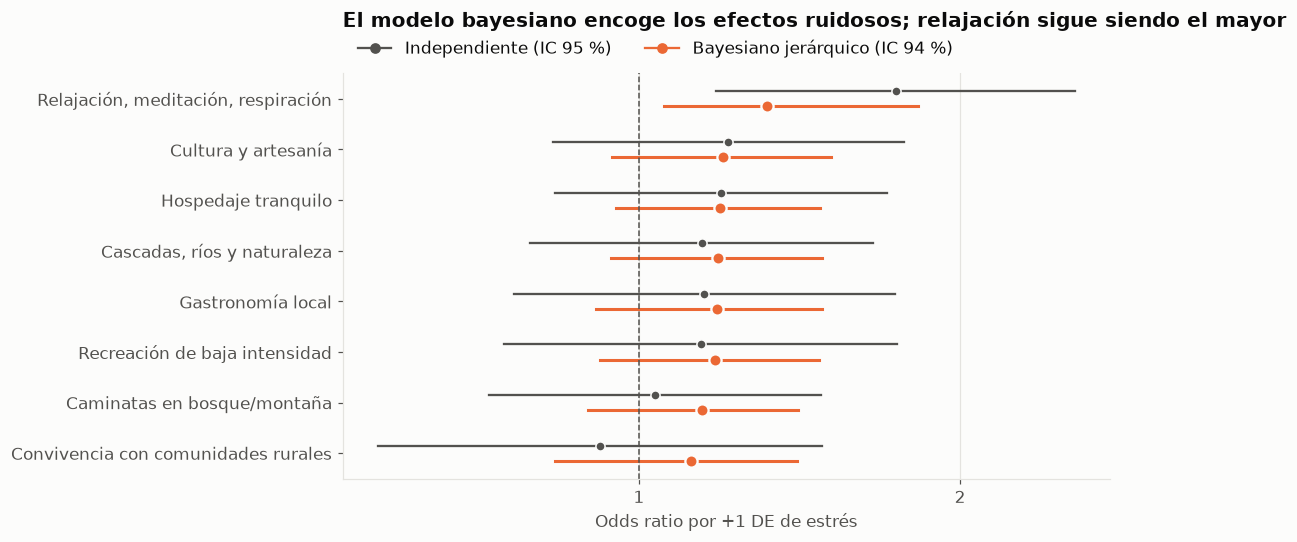

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.8))
y = np.arange(len(tabla))[::-1]
for i, fila in tabla.iterrows():
    yi = y[i]
    ax.plot(fila['IC95 independiente'], [yi + 0.15] * 2, color=TEXTO_2, linewidth=1.5)
    ax.plot(fila['OR independiente'], yi + 0.15, 'o', color=TEXTO_2, markersize=6, markeredgecolor='#fcfcfb')
    ax.plot(fila['IC94 bayesiano'], [yi - 0.15] * 2, color=SERIES[1], linewidth=2)
    ax.plot(fila['OR bayesiano'], yi - 0.15, 'o', color=SERIES[1], markersize=8, markeredgecolor='#fcfcfb', markeredgewidth=1.5)
ax.axvline(1, color=TEXTO_2, linestyle='--', linewidth=1)
ax.set_yticks(y, tabla['tipo']); ax.set_xscale('log'); ax.set_xticks([0.5, 1, 2, 3], ['0.5', '1', '2', '3']); ax.minorticks_off()
ax.grid(axis='y', visible=False); ax.set_xlabel('Odds ratio por +1 DE de estrés')
ax.plot([], [], 'o-', color=TEXTO_2, label='Independiente (IC 95 %)'); ax.plot([], [], 'o-', color=SERIES[1], label='Bayesiano jerárquico (IC 94 %)')
ax.legend(frameon=False, loc='lower left', bbox_to_anchor=(0, 1.0), ncols=2)
ax.set_title('El modelo bayesiano encoge los efectos ruidosos; relajación sigue siendo el mayor', pad=30)
guardar(fig, '10_bayes_vs_independiente');

## Validación cruzada (5 folds × 4 repeticiones, por persona)

In [4]:
pd.DataFrame(cv['metodos']).T

,ndcg@3,logloss,dif_ndcg_vs_popularidad,ic95
popularidad,0.6507,0.6138,NaN,NaN
fdr,0.648,0.6155,-0.0027,"[-0.0094, 0.0042]"
bayes_jerarquico,0.6481,0.6144,-0.0026,"[-0.0106, 0.0054]"


**Lectura.** El modelo bayesiano **empata** con la popularidad y con el modelo FDR (diferencias de nDCG dentro de ±0.01 y log-loss prácticamente igual). Como prueba de robustez confirma lo mismo con otro método: relajación es el efecto más fuerte (P > 0.99). Se mantiene el modelo FDR en producción por ser el más simple con igual desempeño.

## Hallazgo nuevo: más estrés, más amplitud de interés
El efecto promedio compartido μ_b es positivo: con más estrés la gente **elige más tipos de experiencia** de bienestar, no solo relajación.

,mean,sem,size
nivel,,,
Bajo,2.57,0.22,42
Medio,3.24,0.24,45
Alto,3.33,0.28,39


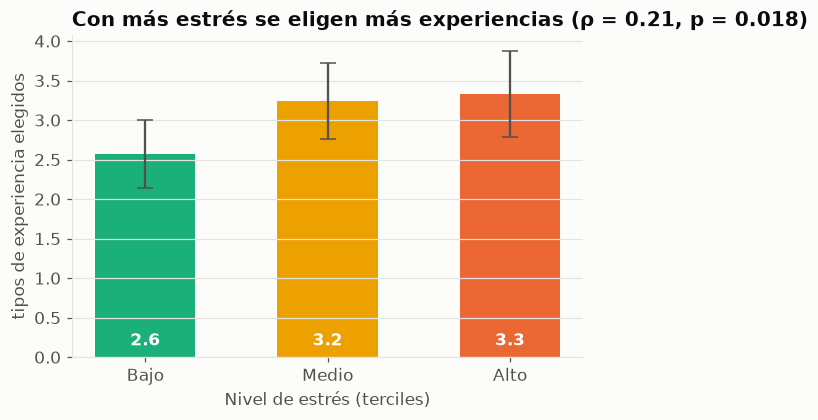

In [5]:
d = pd.read_csv(OUT_DEFAULT).dropna(subset=['estres_0_100']).copy()
d['n_tipos'] = d[PREFERENCIAS].sum(axis=1)
rho = spearmanr(d['estres_0_100'], d['n_tipos'])
d['nivel'] = pd.qcut(d['estres_0_100'], 3, labels=['Bajo', 'Medio', 'Alto'])
g = d.groupby('nivel', observed=True)['n_tipos'].agg(['mean', 'sem', 'size'])
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.bar(g.index.astype(str), g['mean'], yerr=1.96 * g['sem'], color=[SERIES[2], SERIES[3], SERIES[1]], width=0.55, capsize=5, error_kw={'ecolor': TEXTO_2})
for i, v in enumerate(g['mean']):
    ax.text(i, 0.15, f'{v:.1f}', ha='center', color='white', fontweight='bold')
ax.set_xlabel('Nivel de estrés (terciles)'); ax.set_ylabel('tipos de experiencia elegidos'); ax.grid(axis='x', visible=False)
ax.set_title(f'Con más estrés se eligen más experiencias (ρ = {rho.statistic:.2f}, p = {rho.pvalue:.3f})')
guardar(fig, '10_amplitud_por_estres');
g.round(2)

## Contexto GWI (Global Wellness Institute)
GWI **no publica microdatos** (personas o lugares), por lo que no entrena el modelo; aporta el contexto de mercado y el marco conceptual.

| Dato | Valor | Fuente |
|---|---|---|
| Turismo de bienestar global 2024 | US$893.9 mil millones; 6.4 % anual 2019-2024; proyección 9.1 % anual a 2029 | GWI, *Global Wellness Economy Monitor 2025* |
| **México: turismo de bienestar 2024** | **US$16.7 mil millones, 19.0 millones de viajes, n.º 12 del mundo**; +7.6 % 2023-2024 | Monitor 2025, Fig. 9.4 |
| México: economía del bienestar 2024 | US$98.1 mil millones, n.º 15 del mundo; 9.8 % anual 2019-2024 | GWI, *Country Rankings* (ene-2026), Fig. 3.1 |
| Viajeros secundarios (el bienestar no es el motivo principal del viaje) | la gran mayoría de los viajes de bienestar | GWI, *What is wellness tourism* |

**Implicación de diseño:** como la mayoría de los viajeros de bienestar son *secundarios*, WELLTUR mezcla experiencias wellness con hospedaje, gastronomía y cultura locales en lugar de limitarse a spas — y eso es justo lo que permite incluir a las MiPyMEs.